# Q10: Data Wrangling

**Problem Statement:** Data Wrangling on Real Estate Market

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt

homes = pd.read_csv("RealEstate_Prices.csv")
amenities = pd.read_csv("RealEstate_Neighborhoods.csv")
print("Raw shape:", homes.shape)
print(homes.head().to_string(index=False))
print("Missing values:\n", homes.isna().sum().to_string())


Raw shape: (240, 8)
Property ID  Sale Date Neighborhood Property Type  Area SqFt  Bedrooms  Year Built  Sale Price
     RE0001 2024-11-24         West     Apartment     1327.0         2        1990   345888.22
     RE0002 2025-05-03        South         House     1311.0         2        1981   254684.47
     RE0003 2024-10-02        North     Townhouse     1145.0         2        2007   282201.60
     RE0004 2025-01-06        North     Apartment     1717.0         3        2018   406372.48
     RE0005 2023-12-23         West     Townhouse      719.0         1        2019   344811.98
Missing values:
 Property ID      0
Sale Date        0
Neighborhood     0
Property Type    0
Area SqFt        1
Bedrooms         0
Year Built       0
Sale Price       0


In [2]:
# Clean column names and types; fill the missing area with the median.
homes.columns = [re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_") for name in homes.columns]
homes["sale_date"] = pd.to_datetime(homes["sale_date"], errors="coerce")
homes["neighborhood"] = homes["neighborhood"].astype(str).str.strip().str.title()
homes["area_sqft"] = homes["area_sqft"].fillna(homes["area_sqft"].median())
homes = homes.dropna(subset=["sale_date", "sale_price"])
print("Clean columns:", homes.columns.tolist())


Clean columns: ['property_id', 'sale_date', 'neighborhood', 'property_type', 'area_sqft', 'bedrooms', 'year_built', 'sale_price']


In [3]:
# Merge neighborhood amenities and select a recent subset.
homes = homes.merge(amenities, left_on="neighborhood", right_on="Neighborhood", how="left", validate="many_to_one")
homes = homes.drop(columns="Neighborhood")
recent = homes.loc[homes["sale_date"] >= "2024-01-01"].copy()
print("Recent properties:", len(recent))
print(recent[["neighborhood", "NearbyAmenities"]].head().to_string(index=False))


Recent properties: 124
neighborhood  NearbyAmenities
        West                7
       South                4
       North                5
       North                5
     Central                8


In [4]:
# Cap unusually high prices and derive price per square foot.
q1, q3 = recent["sale_price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("Prices above IQR upper bound:", int((recent["sale_price"] > upper).sum()))
recent["sale_price_capped"] = recent["sale_price"].clip(upper=upper)
recent["price_per_sqft"] = recent["sale_price_capped"] / recent["area_sqft"]
print(recent.groupby("neighborhood")["sale_price_capped"].agg(["count", "mean", "median"]).round(2).to_string())


Prices above IQR upper bound: 1
              count       mean     median
neighborhood                             
Central          30  523646.54  534323.86
North            39  390297.44  392842.99
South            27  324892.40  332545.07
West             28  489647.20  492930.45


Encoded feature columns: ['area_sqft', 'bedrooms', 'year_built', 'NearbyAmenities', 'neighborhood_North', 'neighborhood_South', 'neighborhood_West', 'property_type_House', 'property_type_Townhouse']


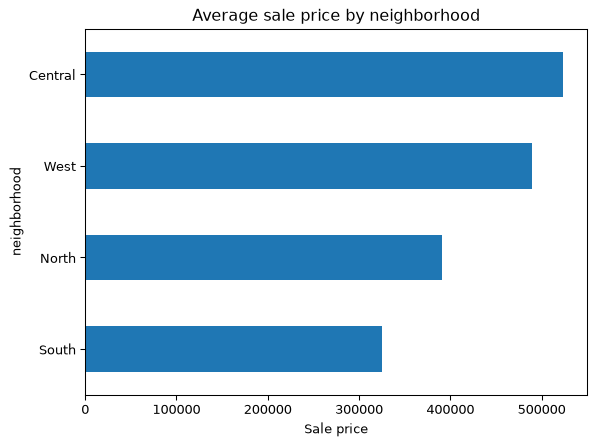

In [5]:
# Encode categorical columns for later modeling and compare neighborhoods.
model_features = pd.get_dummies(recent[["neighborhood", "property_type", "area_sqft", "bedrooms", "year_built", "NearbyAmenities"]], drop_first=True, dtype=int)
print("Encoded feature columns:", model_features.columns.tolist())
recent.groupby("neighborhood")["sale_price_capped"].mean().sort_values().plot.barh(title="Average sale price by neighborhood")
plt.xlabel("Sale price")
plt.tight_layout()
plt.show()
